## Helper functions

### Helper function to visualize the images with their respective RGB 3D distribution

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objs as go

def visualize_images_and_distributions(source, target, result, subsample_factor=10, interactive_plot=False):
    """
    Display source, target, and result images (top row)
    and their RGB color distributions (bottom row).

    Parameters
    ----------
    source, target, result : np.ndarray
        Input images in RGB format (values in [0, 1] or [0, 255]).
    subsample_factor : int, optional
        Factor by which to subsample pixels for faster visualization (default=10).
    interactive_plot : bool, optional
        If True, shows Plotly 3D interactive color distributions (separate windows).
        If False, shows them in static Matplotlib 3D plots.
    """

    def preprocess_image(img):
        """Ensure image is float in [0,1] and flattened."""
        if img.dtype == np.uint8:
            img = img / 255.0
        X = img.reshape((-1, 3))
        if subsample_factor > 1:
            nb = int(X.shape[0] / subsample_factor)
            r = np.random.RandomState(42)
            idx = r.randint(X.shape[0], size=(nb,))
            X = X[idx, :]
        return X

    # Prepare data
    imgs = {
        "Source": (source, preprocess_image(source)),
        "Target": (target, preprocess_image(target)),
        "Result": (result, preprocess_image(result))
    }

    # === Create a 2x3 Matplotlib figure ===
    fig = plt.figure(figsize=(15, 10), constrained_layout=True)

    # --- Top row: original images ---
    for i, (title, (img, _)) in enumerate(imgs.items(), start=1):
        ax = fig.add_subplot(2, 3, i)
        ax.imshow(img)
        ax.set_title(title)
        ax.axis("off")

    # --- Bottom row: 3D RGB distributions ---
    for i, (title, (_, Xs)) in enumerate(imgs.items(), start=1):
        ax = fig.add_subplot(2, 3, i + 3, projection='3d')
        ax.scatter(Xs[:, 0], Xs[:, 1], Xs[:, 2], c=Xs, s=8)
        ax.set_xlabel("R")
        ax.set_ylabel("G")
        ax.set_zlabel("B")
        ax.set_title(f"{title} RGB Distribution")
        ax.view_init(elev=20, azim=135)

    fig.suptitle("Image Comparison and 3D RGB Distributions", fontsize=15, y=0.98)
    plt.show()

    # === Optional interactive version ===
    if interactive_plot:
        for title, (_, Xs) in imgs.items():
            fig_plotly = go.Figure(data=[go.Scatter3d(
                x=Xs[:, 0],
                y=Xs[:, 1],
                z=Xs[:, 2],
                mode='markers',
                marker=dict(
                    size=2,
                    color=['rgb({},{},{})'.format(int(r*255), int(g*255), int(b*255))
                           for r, g, b in Xs]
                )
            )])
            fig_plotly.update_layout(
                scene=dict(xaxis_title='R', yaxis_title='G', zaxis_title='B'),
                width=700,
                height=600,
                title=f"3D RGB Distribution ({title})"
            )
            fig_plotly.show()


## Mean and covariance matching method

### Import the Libraries

In [8]:
import numpy as np
import cv2
from skimage import io, color

### Define the color transfer function

In [9]:
import numpy as np
from skimage import io

def affine_color_transfer(src_path, tgt_path):
    """
    Affine color transfer working purely in RGB.
    Prints mean & covariance of source, target, and result (before clipping).
    Output is uint8 RGB in [0,255].
    """

    # --- Load images ---
    src = io.imread(src_path).astype(np.float64)
    tgt = io.imread(tgt_path).astype(np.float64)

    # --- Normalize to [0,1] ---
    if src.max() > 1.0: src /= 255.0
    if tgt.max() > 1.0: tgt /= 255.0

    # --- Flatten ---
    H, W, C = src.shape
    Xs = src.reshape(-1, 3)
    Xt = tgt.reshape(-1, 3)

    # --- Means ---
    mu_s = Xs.mean(axis=0)
    mu_t = Xt.mean(axis=0)

    # --- Covariances ---
    Sigma_s = np.cov(Xs, rowvar=False, bias=True)
    Sigma_t = np.cov(Xt, rowvar=False, bias=True)

    eps = 1e-5

    # Regularize if needed
    eig_s = np.linalg.eigvalsh(Sigma_s)
    eig_t = np.linalg.eigvalsh(Sigma_t)

    if np.any(eig_s <= 1e-10):
        Sigma_s += eps * np.eye(3)
    if np.any(eig_t <= 1e-10):
        Sigma_t += eps * np.eye(3)

    # --- Whitening transform Σ_s^{-1/2} ---
    Ds, Us = np.linalg.eigh(Sigma_s)
    Ds_inv_sqrt = np.diag(1.0 / np.sqrt(Ds))
    Sigma_s_inv_sqrt = Us @ Ds_inv_sqrt @ Us.T

    # --- Coloring transform Σ_t^{1/2} ---
    Dt, Ut = np.linalg.eigh(Sigma_t)
    Dt_sqrt = np.diag(np.sqrt(Dt))
    Sigma_t_sqrt = Ut @ Dt_sqrt @ Ut.T

    # --- Affine transformation matrix ---
    A = Sigma_t_sqrt @ Sigma_s_inv_sqrt

    # --- Apply transformation (before clipping!) ---
    Y = (Xs - mu_s) @ A.T + mu_t   # <--- BEFORE CLIP

    # === PRINT STATISTICS ===
    mu_r = Y.mean(axis=0)
    Sigma_r = np.cov(Y, rowvar=False, bias=True)

    print("\n===== SOURCE =====")
    print("Mean:\n", mu_s)
    print("Covariance:\n", Sigma_s)

    print("\n===== TARGET =====")
    print("Mean:\n", mu_t)
    print("Covariance:\n", Sigma_t)

    print("\n===== RESULT (before clipping) =====")
    print("Mean:\n", mu_r)
    print("Covariance:\n", Sigma_r)

    # --- Clip & reshape ---
    Y = np.clip(Y, 0, 1).reshape(H, W, 3)

    # --- Convert back to uint8 ---
    return (Y * 255.0 + 0.5).astype(np.uint8)


### Test

In [11]:
source = io.imread("ColabFiles/source.jpg").astype(np.float64)/255
target = io.imread("ColabFiles/target.jpg").astype(np.float64)/255

result = affine_color_transfer("ColabFiles/source.jpg", "ColabFiles/target.jpg")
result = result.astype(np.float64)/255



===== SOURCE =====
Mean:
 [0.54146444 0.48456544 0.43353309]
Covariance:
 [[0.02297969 0.02092757 0.02024097]
 [0.02092757 0.02486936 0.02614626]
 [0.02024097 0.02614626 0.02888781]]

===== TARGET =====
Mean:
 [0.61045728 0.55546412 0.45481971]
Covariance:
 [[0.07374692 0.03952299 0.01011889]
 [0.03952299 0.03872321 0.02267423]
 [0.01011889 0.02267423 0.03144722]]

===== RESULT (before clipping) =====
Mean:
 [0.61045728 0.55546412 0.45481971]
Covariance:
 [[0.07374692 0.03952299 0.01011889]
 [0.03952299 0.03872321 0.02267423]
 [0.01011889 0.02267423 0.03144722]]


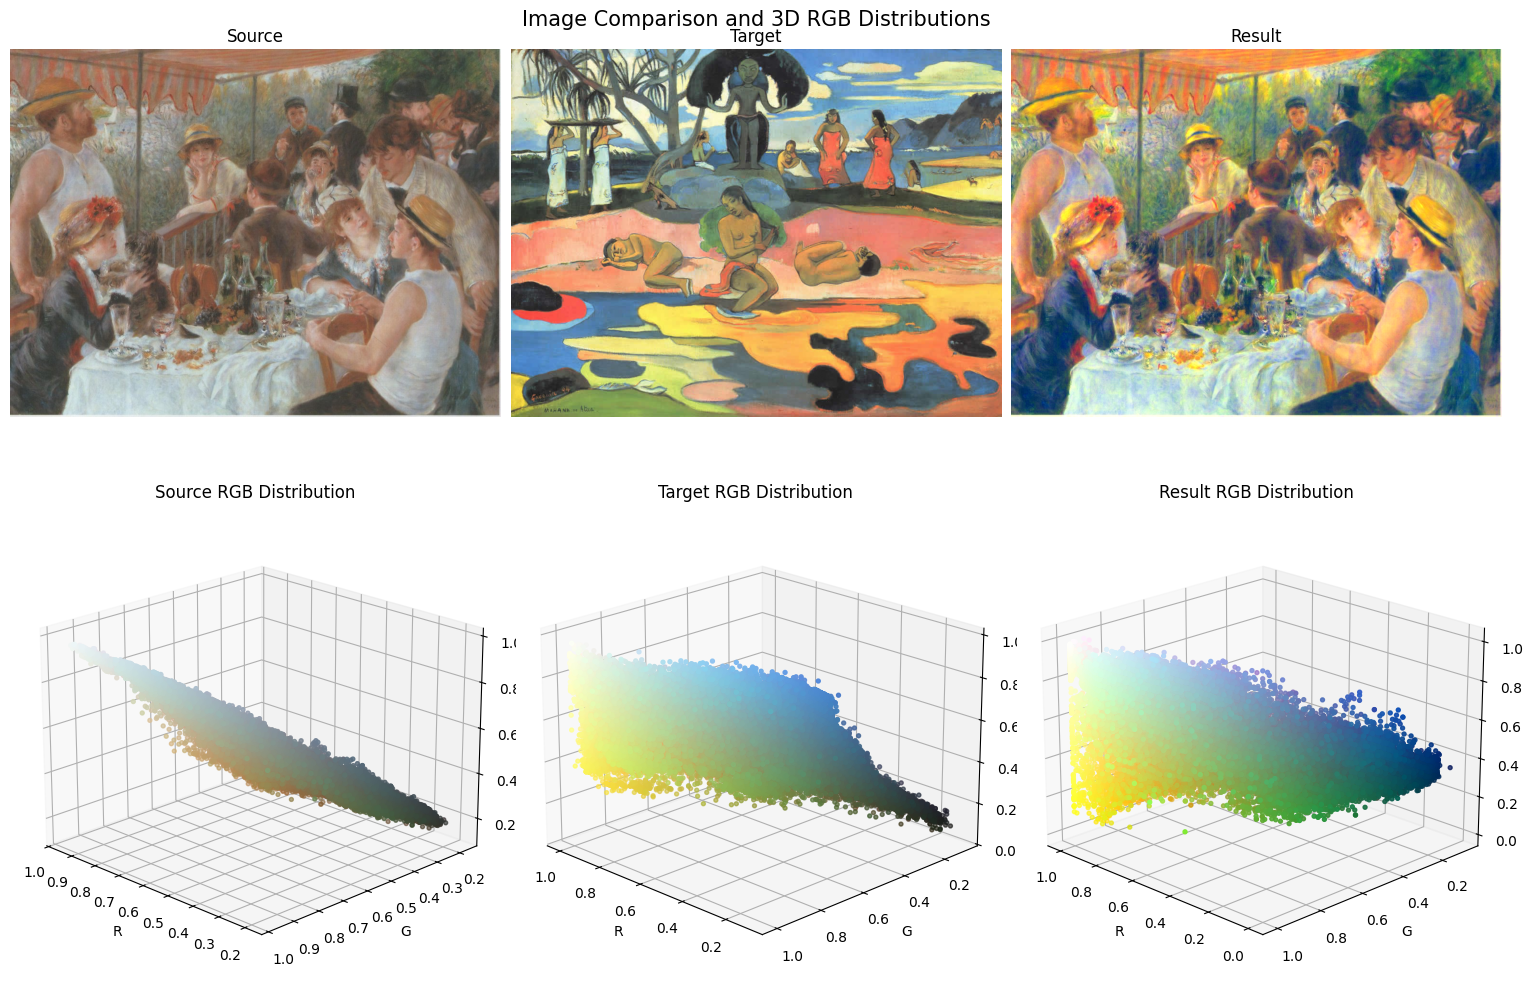

In [12]:
visualize_images_and_distributions(source, target, result, subsample_factor=10, interactive_plot=False)